# Interpretability 9: Different plotting metrics

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

model = KANNetwork([2,5,1], device=device)
f = lambda x: torch.exp(torch.sin(torch.pi*x[:,[0]]) + x[:,[1]]**2)
train, test = create_dataset(f, n_var=2, device=device)
history = fit(model, train, test, steps = 20, lamb=1e-3)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

cuda


train RMSE 0.016021018239580596 test RMSE 0.015670563715872752


Note: the KAN diagram has three plotting metrics:
* forward_u: the edge's unnormalized "norm" (output std)
* forward_n: the edge's normalized "norm" (output std / input std)
* backward: the edge attribution score (default)

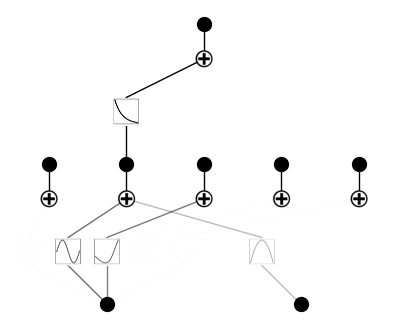

In [2]:
plot(model, train['x'], metric='forward_u');

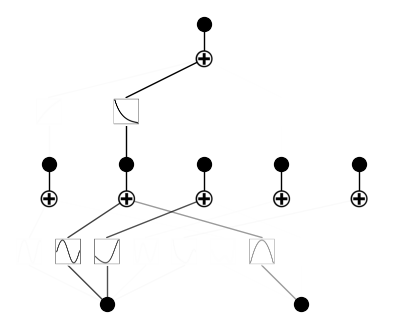

In [3]:
plot(model, train['x'], metric='forward_n');

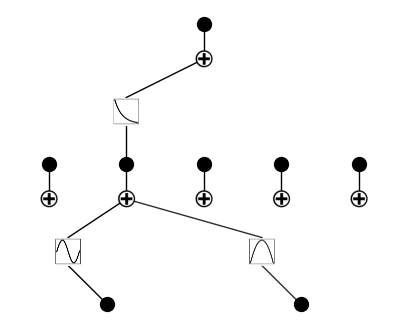

In [4]:
plot(model, train['x'], metric='backward');